# 05 V5 — Class-Wise Error Analysis & Targeted Optimization (CIC-IDS2017)

**Mục tiêu:** cải thiện các lớp khó (`Web Attack`, `Bot`, `DoS Hulk`, `BENIGN`) bằng loss / sampler và calibration dựa trên **validation**. Giữ đúng 19 features, 15 nhãn, chia tập từ Notebook 03. Không có timestamp/IP nên đây vẫn là **exploratory pilot**, không phải benchmark temporal/host-disjoint.

**Nguyên tắc:** `train` dùng cập nhật weights, `validation` dùng error analysis / chọn model / calibration, `test` chỉ dùng một lần sau khi khóa cấu hình. Test V1–V4 đã từng được xem; ngay cả V5 test cũng **không độc lập** cho suy luận nghiên cứu cuối. Không ghép mở rộng features bằng thứ tự dòng.

**Chế độ:** `fast` chạy smoke trial, `balanced` mặc định chạy 8 trials, `full` 12 trials. Có thể chạy lại nếu Kaggle ngắt, nhưng output trong `/kaggle/working` cần Save Version để lưu.

## 1 — Thiết lập Kaggle, GPU và thư mục kết quả

In [72]:
from pathlib import Path
import os, json, time, random, hashlib, gc, warnings
from copy import deepcopy
from dataclasses import asdict, dataclass
import numpy as np, pandas as pd, torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (accuracy_score, f1_score, balanced_accuracy_score,
    precision_score, recall_score, classification_report, confusion_matrix)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler, LabelEncoder
import joblib

SEED = 42
SEARCH_MODE = 'balanced'  # fast | balanced | full
OUTPUT = Path('/kaggle/working/nids_outputs/05_CNN_Ablation_V5_ClassWise')
OUTPUT.mkdir(parents=True,exist_ok=True)
SPLIT_PATH = None  # optional explicit override
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
print('Torch:',torch.__version__,'| Device:',DEVICE)
if DEVICE.type=='cuda': print('GPU:',torch.cuda.get_device_name(0))
assert SEARCH_MODE in {'fast','balanced','full'}
BUDGET={
 'fast': {'epochs':6,'patience':3,'trials_each':1,'seeds':[42]},
 'balanced': {'epochs':65,'patience':10,'trials_each':1,'seeds':[42,43]},
 'full': {'epochs':90,'patience':12,'trials_each':1,'seeds':[42,43,44]}
}[SEARCH_MODE]
print('Budget:',BUDGET)
def set_seed(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)
set_seed(SEED)

FPR_TARGET = 0.10  # validation attack-vs-BENIGN FPR target; can be infeasible

FPR_TARGET = 0.10
WEB_LABEL_FRAGMENTS=('Web Attack','Bot','DoS Hulk')


Torch: 2.11.0+cu130 | Device: cuda
GPU: Tesla T4
Budget: {'epochs': 65, 'patience': 10, 'trials_each': 1, 'seeds': [42, 43]}


## 2 — Load split Notebook 03; không tự resample

In [73]:
if SPLIT_PATH is None:
    local=Path('/kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet')
    matches=([local] if local.is_file() else sorted(Path('/kaggle/input').rglob('cic_pilot_splits.parquet')))
    if not matches:
        raise FileNotFoundError('Thiếu cic_pilot_splits.parquet. Hãy Save Version Notebook 03 rồi Add Input output. Không tự tạo split mới.')
    if len(matches)>1:
        raise ValueError(f'Nhiều split được tìm thấy, hãy chỉ định SPLIT_PATH: {matches}')
    split_path=matches[0]
else: split_path=Path(SPLIT_PATH)
assert split_path.is_file(),split_path
sample=pd.read_parquet(split_path)
required={'Label','_split','_binary_label'}
assert required.issubset(sample.columns),f'Missing columns: {required-set(sample.columns)}'
features=[c for c in sample.columns if c not in required]
assert len(features)==19,('Expected exactly 19 features',features)
split=sample['_split'].astype(str)
assert set(split.unique())=={'train','validation','test'}
labels=sample['Label'].astype(str)
assert np.array_equal((labels!='BENIGN').astype(int).to_numpy(),sample['_binary_label'].astype(int).to_numpy())
idx={key:split.eq(key).to_numpy() for key in ['train','validation','test']}
assert 'BENIGN' in set(labels[idx['train']])
encoder=LabelEncoder().fit(labels[idx['train']])
if set(encoder.classes_)!=set(labels): raise ValueError('Train thiếu classes xuất hiện trong val/test; phải sửa upstream split')
y={part:encoder.transform(labels[mask]).astype(np.int64) for part,mask in idx.items()}
raw=sample[features].apply(pd.to_numeric,errors='coerce').replace([np.inf,-np.inf],np.nan)
sha=hashlib.sha256(split_path.read_bytes()).hexdigest()
print('File:',split_path,'| SHA256:',sha)
print('Features:',features)
print('Split:',{part:int(mask.sum()) for part,mask in idx.items()})
print('Classes:',len(encoder.classes_))
print(pd.crosstab(labels,split).to_string())
# Preserve split provenance; do not look at test features/labels to fit preprocessing.


File: /kaggle/working/nids_outputs/03_Gaussian_Anomaly/cic_pilot_splits.parquet | SHA256: 14304c159bdd8ffecd321fe4e132db4f71b921a36c6b5f56fd51cf363ef42b7b
Features: ['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Mean', 'Bwd Packet Length Mean', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'ACK Flag Count', 'Average Packet Size', 'Active Mean', 'Idle Mean']
Split: {'train': 9432, 'validation': 3144, 'test': 3144}
Classes: 15
_split                        test  train  validation
Label                                                
BENIGN                        1000   3000        1000
Bot                            213    597         190
DDoS                           203    585         212
DoS GoldenEye                  209    611         180
DoS Hulk                       190    630         180

## 3 — Preprocessing fit trên train; validation/test chỉ transform

In [74]:
preprocess={}; X={}
for scaler_name,scaler in [('standard',StandardScaler()),('robust',RobustScaler())]:
    imputer=SimpleImputer(strategy='median',keep_empty_features=True)
    xtr=imputer.fit_transform(raw.loc[idx['train']])
    xtr=scaler.fit_transform(xtr)
    arrays={'train':xtr.astype(np.float32)}
    for part in ['validation','test']:
        arrays[part]=scaler.transform(imputer.transform(raw.loc[idx[part]])).astype(np.float32)
    assert all(np.isfinite(v).all() for v in arrays.values())
    preprocess[scaler_name]={'imputer':imputer,'scaler':scaler}
    X[scaler_name]=arrays
counts=np.bincount(y['train'],minlength=len(encoder.classes_))
print('Train class counts:',dict(zip(encoder.classes_.tolist(),counts.tolist())))
print('Preprocessing fit on train only; validation/test transforms only.')


Train class counts: {'BENIGN': 3000, 'Bot': 597, 'DDoS': 585, 'DoS GoldenEye': 611, 'DoS Hulk': 630, 'DoS Slowhttptest': 595, 'DoS slowloris': 611, 'FTP-Patator': 592, 'Heartbleed': 6, 'Infiltration': 18, 'PortScan': 611, 'SSH-Patator': 590, 'Web Attack ï¿½ Brute Force': 599, 'Web Attack ï¿½ Sql Injection': 10, 'Web Attack ï¿½ XSS': 377}
Preprocessing fit on train only; validation/test transforms only.


## 4 — Kiến trúc A5, giữ kiến trúc V4 để so sánh có kiểm soát

In [75]:
class SEBlock(nn.Module):
    def __init__(self,c,reduction=8):
        super().__init__()
        self.net=nn.Sequential(nn.AdaptiveAvgPool1d(1),nn.Flatten(),
            nn.Linear(c,max(4,c//reduction)),nn.ReLU(),nn.Linear(max(4,c//reduction),c),nn.Sigmoid())
    def forward(self,z):return z*self.net(z).unsqueeze(-1)

class AttentionPool(nn.Module):
    def __init__(self,c):
        super().__init__();self.score=nn.Sequential(nn.Linear(c,max(8,c//2)),nn.Tanh(),nn.Linear(max(8,c//2),1))
    def forward(self,z):
        h=z.transpose(1,2)
        w=torch.softmax(self.score(h).squeeze(-1),dim=1)
        return (h*w.unsqueeze(-1)).sum(dim=1)

class BasicFeatureCNN(nn.Module):
    def __init__(self,f,k,use_se=False,use_attn=False,width=64,dropout=.2):
        super().__init__();self.f=f
        self.conv=nn.Sequential(nn.Conv1d(1,width,3,padding=1),nn.ReLU(),nn.Conv1d(width,width,3,padding=1),nn.ReLU())
        self.se=SEBlock(width) if use_se else nn.Identity()
        self.pool=AttentionPool(width) if use_attn else nn.AdaptiveAvgPool1d(1)
        self.head=nn.Sequential(nn.Linear(width,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):
        z=self.se(self.conv(x.unsqueeze(1)))
        h=self.pool(z)
        if h.ndim==3:h=h.squeeze(-1)
        return self.head(h)

class ResConvBlock(nn.Module):
    def __init__(self,c,dropout):
        super().__init__()
        self.net=nn.Sequential(nn.Conv1d(c,c,3,padding=1),nn.BatchNorm1d(c),nn.GELU(),
                nn.Conv1d(c,c,3,padding=1),nn.BatchNorm1d(c))
        self.drop=nn.Dropout1d(dropout)
    def forward(self,x):return torch.nn.functional.gelu(x+self.drop(self.net(x)))

class MultiScaleResidualCNN(nn.Module):
    def __init__(self,f,k,width=64,dropout=.2,use_se=True,use_attn=True,hybrid=False):
        super().__init__();self.f=f;self.hybrid=hybrid
        self.multi=nn.ModuleList([nn.Conv1d(1,width,sz,padding=sz//2) for sz in [1,3,5]])
        self.proj=nn.Sequential(nn.Conv1d(width*3,width,1),nn.BatchNorm1d(width),nn.GELU())
        self.blocks=nn.Sequential(ResConvBlock(width,dropout),ResConvBlock(width,dropout))
        self.se=SEBlock(width) if use_se else nn.Identity()
        self.pool=AttentionPool(width) if use_attn else nn.AdaptiveAvgPool1d(1)
        # Attention + avg/max retain both focused and global information.
        merged=width*3
        if hybrid:
            self.raw_path=nn.Sequential(nn.Linear(f,128),nn.LayerNorm(128),nn.GELU(),
                          nn.Dropout(dropout),nn.Linear(128,width),nn.GELU())
            merged+=width
        self.head=nn.Sequential(nn.Linear(merged,128),nn.GELU(),nn.Dropout(dropout),
                                nn.Linear(128,64),nn.GELU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):
        z=self.proj(torch.cat([part(x.unsqueeze(1)) for part in self.multi],dim=1))
        z=self.se(self.blocks(z))
        h=self.pool(z)
        if h.ndim==3:h=h.squeeze(-1)
        pieces=[h,z.mean(-1),z.amax(-1)]
        if self.hybrid:pieces.append(self.raw_path(x))
        return self.head(torch.cat(pieces,dim=1))

class MLPBaseline(nn.Module):
    def __init__(self,f,k,dropout=.2,width=128):
        super().__init__()
        self.net=nn.Sequential(nn.Linear(f,width),nn.ReLU(),nn.Dropout(dropout),
             nn.Linear(width,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,k))
    def forward(self,x):return self.net(x)

ARCHS=['MLP','A0_CNN','A1_CNN_SE','A2_CNN_FeatureAttn','A3_CNN_SE_FeatureAttn',
       'A4_MultiScaleRes_SE_Attn','A5_HybridMultiScaleRes_SE_Attn']
def build_model(arch,width=64,dropout=.2):
    f=len(features);k=len(encoder.classes_)
    if arch=='MLP':return MLPBaseline(f,k,dropout,width=max(128,width))
    if arch.startswith('A0_'):return BasicFeatureCNN(f,k,False,False,width,dropout)
    if arch.startswith('A1_'):return BasicFeatureCNN(f,k,True,False,width,dropout)
    if arch.startswith('A2_'):return BasicFeatureCNN(f,k,False,True,width,dropout)
    if arch.startswith('A3_'):return BasicFeatureCNN(f,k,True,True,width,dropout)
    if arch.startswith('A4_'):return MultiScaleResidualCNN(f,k,width,dropout,hybrid=False)
    if arch=='A5_HybridMultiScaleRes_SE_Attn':return MultiScaleResidualCNN(f,k,width,dropout,True,True,True)
    if arch=='A5_no_SE':return MultiScaleResidualCNN(f,k,width,dropout,False,True,True)
    if arch=='A5_no_Attn':return MultiScaleResidualCNN(f,k,width,dropout,True,False,True)
    if arch=='A5_no_Raw':return MultiScaleResidualCNN(f,k,width,dropout,True,True,False)
    if arch=='A5_backbone_only':return MultiScaleResidualCNN(f,k,width,dropout,False,False,False)
    raise ValueError(arch)

for a in ['A5_HybridMultiScaleRes_SE_Attn','A5_no_SE','A5_no_Attn','A5_no_Raw','A5_backbone_only']:
    m=build_model(a)
    assert m(torch.randn(2,len(features))).shape==(2,len(encoder.classes_))
    print(f'{a}: {sum(p.numel() for p in m.parameters()):,} parameters')


A5_HybridMultiScaleRes_SE_Attn: 119,576 parameters
A5_no_SE: 118,480 parameters
A5_no_Attn: 117,463 parameters
A5_no_Raw: 100,312 parameters
A5_backbone_only: 97,103 parameters


## 5 — Phân tích dữ liệu và lớp khó (chỉ train / validation)

Phân phối nhãn, số lượng nhỏ và feature separability được tính từ train. `Heartbleed`, `SQL Injection` hoặc `Infiltration` rất ít mẫu: không nhân bản quá mức hay đưa ra tuyên bố chắc chắn về khả năng khái quát hóa.

In [76]:
from sklearn.feature_selection import f_classif
from IPython.display import display
counts_train=pd.Series(y['train']).value_counts().reindex(class_ids if 'class_ids' in globals() else np.arange(len(encoder.classes_)),fill_value=0)
counts_val=pd.Series(y['validation']).value_counts().reindex(np.arange(len(encoder.classes_)),fill_value=0)
class_stats=pd.DataFrame({'class_name':encoder.classes_,'train_n':counts_train.values,'validation_n':counts_val.values})
class_stats['risk']=np.where(class_stats.train_n<30,'very_low_support',np.where(class_stats.train_n<100,'low_support','standard'))
class_stats.to_csv(OUTPUT/'class_support_train_validation.csv',index=False)
display(class_stats)
# Train-only ANOVA for diagnostics (not a selection rule); no test statistics.
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    fvals,_=f_classif(X['standard']['train'],y['train'])
pd.DataFrame({'feature':features,'train_anova_f':np.nan_to_num(fvals,nan=0,posinf=0)}).sort_values('train_anova_f',ascending=False).to_csv(OUTPUT/'train_feature_anova.csv',index=False)


,class_name,train_n,validation_n,risk
0,BENIGN,3000,1000,standard
1,Bot,597,190,standard
2,DDoS,585,212,standard
3,DoS GoldenEye,611,180,standard
4,DoS Hulk,630,180,standard
5,DoS Slowhttptest,595,203,standard
6,DoS slowloris,611,208,standard
7,FTP-Patator,592,200,standard
8,Heartbleed,6,3,very_low_support
9,Infiltration,18,9,very_low_support


## 6 — Training loop: CE/Focal, class-aware weights, optional balanced sampler

- Trọng số lớp được tạo từ **train counts**, có `clip` tránh cực đoan khi lớp chỉ có vài mẫu.
- `target_boost` ưu tiên `Web Attack`, `Bot`, `DoS Hulk` nhưng **chỉ chọn mức boost theo validation**, không dùng test.
- WeightedRandomSampler chỉ chọn mẫu từ tập train và có cap. 
- Không kết hợp sampling cực đoan với weights cực đoan.

In [77]:
from dataclasses import dataclass, asdict
from torch.utils.data import WeightedRandomSampler
from sklearn.metrics import precision_recall_fscore_support

@dataclass(frozen=True)
class Config:
    arch: str='A5_HybridMultiScaleRes_SE_Attn'
    seed: int=42
    scaler: str='standard'
    lr: float=.0015
    wd: float=.0001
    width: int=96
    dropout: float=.10
    batch_size: int=256
    weight_power: float=.35
    target_boost: float=1.0
    loss: str='ce'
    use_sampler: bool=False

CLASS_IDS=np.arange(len(encoder.classes_))
BENIGN_ID=int(encoder.transform(['BENIGN'])[0])
TARGET_IDS=[i for i,name in enumerate(encoder.classes_) if any(token.lower() in name.lower() for token in WEB_LABEL_FRAGMENTS)]
print('Target classes:',[encoder.classes_[i] for i in TARGET_IDS])

def weight_vector(cfg):
    count=np.bincount(y['train'],minlength=len(encoder.classes_)).astype(float)
    assert (count>0).all()
    w=(np.median(count)/count)**cfg.weight_power
    w=np.clip(w,.25,8.0)
    w[TARGET_IDS]*=cfg.target_boost
    w=np.clip(w,.25,10.0)
    w=w/w.mean()
    return torch.tensor(w,dtype=torch.float32,device=DEVICE)

class FocalLoss(nn.Module):
    def __init__(self,weights,gamma=1.5):
        super().__init__();self.register_buffer('w',weights);self.gamma=gamma
    def forward(self,logit,target):
        logp=nn.functional.log_softmax(logit,dim=1)
        lp=logp.gather(1,target[:,None]).squeeze(1)
        factors=(1-lp.exp()).pow(self.gamma)
        terms=-factors*lp*self.w[target]
        return terms.sum()/self.w[target].sum().clamp_min(1)

def criterion_for(cfg):
    w=weight_vector(cfg)
    return nn.CrossEntropyLoss(weight=w) if cfg.loss=='ce' else FocalLoss(w)

def loader(part,cfg,epoch=0):
    ds=TensorDataset(torch.from_numpy(X[cfg.scaler][part]),torch.from_numpy(y[part]))
    sampler=None
    if part=='train' and cfg.use_sampler:
        class_n=np.bincount(y['train'],minlength=len(encoder.classes_)).astype(float)
        sample_w=1/np.sqrt(class_n[y['train']]); sample_w=np.minimum(sample_w,np.median(sample_w)*5)
        sampler=WeightedRandomSampler(torch.tensor(sample_w,dtype=torch.double),num_samples=len(ds),replacement=True,
                            generator=torch.Generator().manual_seed(cfg.seed+epoch))
    return DataLoader(ds,batch_size=cfg.batch_size,shuffle=(part=='train' and sampler is None),sampler=sampler,
                      generator=torch.Generator().manual_seed(cfg.seed+epoch),pin_memory=DEVICE.type=='cuda',num_workers=0)

@torch.inference_mode()
def get_logits(model,part,cfg):
    model.eval();out=[]
    for xx,_ in loader(part,cfg):out.append(model(xx.to(DEVICE,non_blocking=True)).cpu().numpy())
    return np.concatenate(out)

def scores(true,pred):
    is_attack=true!=BENIGN_ID; predicted_attack=pred!=BENIGN_ID
    tn,fp,fn,tp=confusion_matrix(is_attack,predicted_attack,labels=[False,True]).ravel()
    return {'accuracy':float(accuracy_score(true,pred)),
            'macro_f1':float(f1_score(true,pred,labels=CLASS_IDS,average='macro',zero_division=0)),
            'weighted_f1':float(f1_score(true,pred,labels=CLASS_IDS,average='weighted',zero_division=0)),
            'attack_recall':float(tp/(tp+fn)) if tp+fn else float('nan'),
            'fpr':float(fp/(tn+fp)) if tn+fp else float('nan')}

def classwise(truth,pred):
    precision,recall,f1,support=precision_recall_fscore_support(truth,pred,labels=CLASS_IDS,zero_division=0)
    return pd.DataFrame({'class_name':encoder.classes_,'support':support,'precision':precision,'recall':recall,'f1':f1})

def confusion_pairs(truth,pred):
    bad=truth!=pred
    tab=pd.DataFrame({'true':encoder.inverse_transform(truth[bad]),'predicted':encoder.inverse_transform(pred[bad])})
    if tab.empty:return pd.DataFrame(columns=['true','predicted','count'])
    return tab.groupby(['true','predicted']).size().reset_index(name='count').sort_values('count',ascending=False)

def run_trial(cfg,trial_id):
    set_seed(cfg.seed)
    model=build_model(cfg.arch,cfg.width,cfg.dropout).to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=cfg.lr,weight_decay=cfg.wd)
    schedule=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='max',patience=4,factor=.5,min_lr=1e-5)
    crit=criterion_for(cfg)
    folder=OUTPUT/'trials'/f'{trial_id:03d}_{cfg.arch}_seed{cfg.seed}'
    folder.mkdir(parents=True,exist_ok=True)
    best=(-1.,-1.);best_epoch=0;stale=0;history=[];start=time.perf_counter()
    for ep in range(1,BUDGET['epochs']+1):
        model.train();loss_sum=0.
        for xb,yb in loader('train',cfg,ep):
            xb=xb.to(DEVICE,non_blocking=True);yb=yb.to(DEVICE,non_blocking=True)
            opt.zero_grad(set_to_none=True)
            loss=crit(model(xb),yb)
            if not torch.isfinite(loss):raise FloatingPointError('nonfinite train loss')
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),2.0);opt.step()
            loss_sum+=float(loss.item())*len(yb)
        val_pred=get_logits(model,'validation',cfg).argmax(axis=1)
        m=scores(y['validation'],val_pred)
        schedule.step(m['macro_f1'])
        history.append({'epoch':ep,'train_loss':loss_sum/len(y['train']),**{('val_'+k):v for k,v in m.items()},'lr':opt.param_groups[0]['lr']})
        key=(m['macro_f1'],m['accuracy'])
        if key>best:
            best=key;best_epoch=ep;stale=0
            torch.save({'state_dict':{k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
                'config':asdict(cfg),'epoch':ep,'split_sha256':sha,'features':features,'classes':encoder.classes_.tolist()},folder/'best.pt')
        else:stale+=1
        if ep==1 or ep%10==0 or stale>=BUDGET['patience']:
            print(f'Trial {trial_id} ep={ep} val_f1={m["macro_f1"]:.4f} best={best[0]:.4f} fpr={m["fpr"]:.4f}',flush=True)
        if stale>=BUDGET['patience']:break
    torch.save({'state_dict':{k:v.detach().cpu().clone() for k,v in model.state_dict().items()},
        'config':asdict(cfg),'epoch':ep,'split_sha256':sha},folder/'last.pt')
    pd.DataFrame(history).to_csv(folder/'history.csv',index=False)
    row={**asdict(cfg),'trial_id':trial_id,'best_epoch':best_epoch,'epochs':ep,'best_val_f1':best[0],
         'best_val_accuracy':best[1],'checkpoint':str(folder/'best.pt'),'seconds':round(time.perf_counter()-start,1)}
    del model,opt,crit;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return row


Target classes: ['Bot', 'DoS Hulk', 'Web Attack ï¿½ Brute Force', 'Web Attack ï¿½ Sql Injection', 'Web Attack ï¿½ XSS']


## 7 — Search có ngân sách (chỉ nhìn validation)

`balanced` dùng A5 Full / A5 no Raw, CE / Focal, boost 1.0 / 1.5 và 1 seed mỗi cấu hình (8 trials). `full` bổ sung kiểm tra sampler và 2nd seed. Cấu hình có thể được mở rộng ở một nghiên cứu mới nhưng không nên liên tục kiểm tra test pilot.

In [78]:
from itertools import product
config_list=[]
for arch,loss,boost in product(['A5_HybridMultiScaleRes_SE_Attn','A5_no_Raw'],['ce','focal'],[1.0,1.5]):
    config_list.append(Config(arch=arch,loss=loss,target_boost=boost,seed=42))
if SEARCH_MODE=='fast': config_list=config_list[:2]
elif SEARCH_MODE=='full':
    config_list.extend([Config(arch='A5_no_Raw',loss='ce',target_boost=1.0,seed=43),
                        Config(arch='A5_HybridMultiScaleRes_SE_Attn',loss='ce',target_boost=1.0,seed=43),
                        Config(arch='A5_no_Raw',loss='ce',target_boost=1.0,use_sampler=True,seed=42),
                        Config(arch='A5_no_Raw',loss='focal',target_boost=1.0,use_sampler=True,seed=42)])
print('Trials:',len(config_list))
rows=[]
for i,cfg in enumerate(config_list,1):
    print('Start',i,asdict(cfg),flush=True)
    row=run_trial(cfg,i);rows.append(row)
    pd.DataFrame(rows).to_csv(OUTPUT/'validation_trials.csv',index=False)
trials=pd.DataFrame(rows).sort_values(['best_val_f1','best_val_accuracy'],ascending=False)
display(trials[['trial_id','arch','loss','target_boost','use_sampler','seed','best_epoch','best_val_f1','best_val_accuracy']])


Trials: 8
Start 1 {'arch': 'A5_HybridMultiScaleRes_SE_Attn', 'seed': 42, 'scaler': 'standard', 'lr': 0.0015, 'wd': 0.0001, 'width': 96, 'dropout': 0.1, 'batch_size': 256, 'weight_power': 0.35, 'target_boost': 1.0, 'loss': 'ce', 'use_sampler': False}
Trial 1 ep=1 val_f1=0.3418 best=0.3418 fpr=0.2730
Trial 1 ep=10 val_f1=0.7824 best=0.7824 fpr=0.1790
Trial 1 ep=20 val_f1=0.7954 best=0.8095 fpr=0.1190
Trial 1 ep=30 val_f1=0.7652 best=0.8405 fpr=0.1090
Trial 1 ep=33 val_f1=0.8159 best=0.8405 fpr=0.1260
Start 2 {'arch': 'A5_HybridMultiScaleRes_SE_Attn', 'seed': 42, 'scaler': 'standard', 'lr': 0.0015, 'wd': 0.0001, 'width': 96, 'dropout': 0.1, 'batch_size': 256, 'weight_power': 0.35, 'target_boost': 1.5, 'loss': 'ce', 'use_sampler': False}
Trial 2 ep=1 val_f1=0.3643 best=0.3643 fpr=0.3410
Trial 2 ep=10 val_f1=0.7634 best=0.7756 fpr=0.2150
Trial 2 ep=20 val_f1=0.7862 best=0.7929 fpr=0.1670
Trial 2 ep=30 val_f1=0.7581 best=0.8177 fpr=0.1360
Trial 2 ep=35 val_f1=0.8142 best=0.8177 fpr=0.1330
St

,trial_id,arch,loss,target_boost,use_sampler,seed,best_epoch,best_val_f1,best_val_accuracy
0,1,A5_HybridMultiScaleRes_SE_Attn,ce,1.0,False,42,23,0.840480,0.884542
4,5,A5_no_Raw,ce,1.0,False,42,23,0.831912,0.873728
6,7,A5_no_Raw,focal,1.0,False,42,31,0.825740,0.870865
7,8,A5_no_Raw,focal,1.5,False,42,38,0.818803,0.883588
1,2,A5_HybridMultiScaleRes_SE_Attn,ce,1.5,False,42,25,0.817715,0.871819
5,6,A5_no_Raw,ce,1.5,False,42,17,0.802202,0.879453
3,4,A5_HybridMultiScaleRes_SE_Attn,focal,1.5,False,42,17,0.799774,0.883906
2,3,A5_HybridMultiScaleRes_SE_Attn,focal,1.0,False,42,17,0.791012,0.890267


## 8 — Validation-only class-wise diagnostics + BENIGN calibration

Xuất `validation_classwise.csv` và `validation_confusion_pairs.csv` cho trial tốt nhất trước calibration. Mỗi candidate được chọn theo **validation Macro-F1**; nếu có candidate đạt FPR ≤ 10% trên validation, ưu tiên candidate khả thi. Sau đó lưu cả lựa chọn theo F1 thuần và lựa chọn FPR-constrained.

In [79]:
def load_trial_model(row):
    checkpoint=torch.load(row['checkpoint'],map_location='cpu',weights_only=False)
    assert checkpoint['split_sha256']==sha
    cfg=Config(**checkpoint['config'])
    model=build_model(cfg.arch,cfg.width,cfg.dropout).to(DEVICE)
    model.load_state_dict(checkpoint['state_dict'])
    return model,cfg

def logits_for(row,part):
    model,cfg=load_trial_model(row)
    out=get_logits(model,part,cfg)
    del model;gc.collect()
    if DEVICE.type=='cuda':torch.cuda.empty_cache()
    return out

best_row=trials.iloc[0]
base_val_logits=logits_for(best_row,'validation')
base_val_pred=base_val_logits.argmax(axis=1)
classwise(y['validation'],base_val_pred).to_csv(OUTPUT/'validation_classwise_best_trial.csv',index=False)
confusion_pairs(y['validation'],base_val_pred).to_csv(OUTPUT/'validation_confusion_pairs_best_trial.csv',index=False)
display(classwise(y['validation'],base_val_pred).sort_values('f1').head(15))
display(confusion_pairs(y['validation'],base_val_pred).head(25))

BIAS_GRID=[0.,.25,.5,.75,1.,1.5,2.]
def with_benign_bias(z,b):
    copy=z.copy();copy[:,BENIGN_ID]+=b;return copy.argmax(axis=1)
choices=[]
for _,row in trials.iterrows():
    z=logits_for(row,'validation')
    for bias in BIAS_GRID:
        pred=with_benign_bias(z,bias)
        met=scores(y['validation'],pred)
        choices.append({'trial_id':int(row['trial_id']),'arch':row['arch'],'bias':bias,**met})
choices=pd.DataFrame(choices)
choices.to_csv(OUTPUT/'validation_calibration_grid.csv',index=False)
pure_f1=choices.sort_values(['macro_f1','accuracy'],ascending=False).iloc[0].to_dict()
feasible=choices[choices.fpr<=FPR_TARGET]
fpr_selection=(feasible if len(feasible) else choices).sort_values(['macro_f1','accuracy'],ascending=False).iloc[0].to_dict()
selected=fpr_selection  # explicit operating objective: FPR <= target on validation if feasible
locked={'selection_rule':'FPR <= 10% on validation if feasible, then highest validation Macro-F1',
        'pure_macro_f1_candidate':pure_f1,'selected':selected,
        'fpr_feasible_any':bool(len(feasible)), 'split_sha256':sha}
(OUTPUT/'validation_selection.json').write_text(json.dumps(locked,indent=2,ensure_ascii=False))
print(json.dumps(locked,ensure_ascii=False,indent=2))


,class_name,support,precision,recall,f1
13,Web Attack ï¿½ Sql Injection,4,0.500000,0.500000,0.500000
12,Web Attack ï¿½ Brute Force,191,0.694215,0.439791,0.538462
14,Web Attack ï¿½ XSS,138,0.502538,0.717391,0.591045
9,Infiltration,9,1.000000,0.666667,0.800000
1,Bot,190,0.683636,0.989474,0.808602
8,Heartbleed,3,0.750000,1.000000,0.857143
0,BENIGN,1000,0.935205,0.866000,0.899273
4,DoS Hulk,180,0.986842,0.833333,0.903614
6,DoS slowloris,208,0.918660,0.923077,0.920863
11,SSH-Patator,211,0.901288,0.995261,0.945946


,true,predicted,count
0,BENIGN,Bot,87
32,Web Attack ï¿½ Brute Force,Web Attack ï¿½ XSS,87
37,Web Attack ï¿½ XSS,Web Attack ï¿½ Brute Force,31
13,DoS Hulk,BENIGN,27
5,BENIGN,PortScan,23
31,Web Attack ï¿½ Brute Force,SSH-Patator,17
24,FTP-Patator,DoS slowloris,12
8,BENIGN,Web Attack ï¿½ XSS,11
18,DoS slowloris,BENIGN,8
7,BENIGN,Web Attack ï¿½ Brute Force,6


{
  "selection_rule": "FPR <= 10% on validation if feasible, then highest validation Macro-F1",
  "pure_macro_f1_candidate": {
    "trial_id": 1,
    "arch": "A5_HybridMultiScaleRes_SE_Attn",
    "bias": 0.75,
    "accuracy": 0.8902671755725191,
    "macro_f1": 0.8438480188541073,
    "weighted_f1": 0.8896560742210173,
    "attack_recall": 0.9664179104477612,
    "fpr": 0.11
  },
  "selected": {
    "trial_id": 8,
    "arch": "A5_no_Raw",
    "bias": 1.0,
    "accuracy": 0.9033078880407125,
    "macro_f1": 0.8304621700521512,
    "weighted_f1": 0.8882771347170314,
    "attack_recall": 0.9538246268656716,
    "fpr": 0.05
  },
  "fpr_feasible_any": true,
  "split_sha256": "14304c159bdd8ffecd321fe4e132db4f71b921a36c6b5f56fd51cf363ef42b7b"
}


## 9 — Test pilot (sau khi khóa model): **một lần**

Test này **đã được dùng trong V1–V4**, do đó chỉ dùng để mô tả pilot; không chỉnh tiếp hyperparameter sau khi xem kết quả. Đưa đánh giá thực sự độc lập vào một split theo ngày/host/dataset khác khi có metadata.

In [80]:
selected_row=trials[trials.trial_id==int(selected['trial_id'])].iloc[0]
test_logits=logits_for(selected_row,'test')
test_pred=with_benign_bias(test_logits,float(selected['bias']))
final_scores=scores(y['test'],test_pred)
val_pred=with_benign_bias(logits_for(selected_row,'validation'),float(selected['bias']))
val_scores=scores(y['validation'],val_pred)
result={'test_pilot_metrics':final_scores,'validation_metrics':val_scores,
        'selected':selected,'split_sha256':sha,'class_names':encoder.classes_.tolist(),
        'test_independent':False,
        'warning':'V1-V4 already used this test split. Do not claim unbiased SOTA or an independent benchmark.'}
(OUTPUT/'final_test_pilot_metrics.json').write_text(json.dumps(result,indent=2,ensure_ascii=False))
classwise(y['test'],test_pred).to_csv(OUTPUT/'test_classwise.csv',index=False)
confusion_pairs(y['test'],test_pred).to_csv(OUTPUT/'test_confusion_pairs.csv',index=False)
pd.DataFrame({'true_label':encoder.inverse_transform(y['test']),
              'pred_label':encoder.inverse_transform(test_pred)}).to_csv(OUTPUT/'test_predictions.csv',index=False)
cm=confusion_matrix(y['test'],test_pred,labels=CLASS_IDS)
np.save(OUTPUT/'test_confusion.npy',cm)
joblib.dump({'imputer':preprocess[selected_row['scaler']]['imputer'],
             'scaler':preprocess[selected_row['scaler']]['scaler'],
             'encoder':encoder,'features':features,'split_sha256':sha},OUTPUT/'selected_preprocessing.joblib')
print(json.dumps(result,ensure_ascii=False,indent=2))
display(classwise(y['test'],test_pred).sort_values('f1'))
display(confusion_pairs(y['test'],test_pred).head(25))


{
  "test_pilot_metrics": {
    "accuracy": 0.9029898218829516,
    "macro_f1": 0.7946383223575613,
    "weighted_f1": 0.8885316780310318,
    "attack_recall": 0.9556902985074627,
    "fpr": 0.061
  },
  "validation_metrics": {
    "accuracy": 0.9033078880407125,
    "macro_f1": 0.8304621700521512,
    "weighted_f1": 0.8882771347170314,
    "attack_recall": 0.9538246268656716,
    "fpr": 0.05
  },
  "selected": {
    "trial_id": 8,
    "arch": "A5_no_Raw",
    "bias": 1.0,
    "accuracy": 0.9033078880407125,
    "macro_f1": 0.8304621700521512,
    "weighted_f1": 0.8882771347170314,
    "attack_recall": 0.9538246268656716,
    "fpr": 0.05
  },
  "split_sha256": "14304c159bdd8ffecd321fe4e132db4f71b921a36c6b5f56fd51cf363ef42b7b",
  "class_names": [
    "BENIGN",
    "Bot",
    "DDoS",
    "DoS GoldenEye",
    "DoS Hulk",
    "DoS Slowhttptest",
    "DoS slowloris",
    "FTP-Patator",
    "Heartbleed",
    "Infiltration",
    "PortScan",
    "SSH-Patator",
    "Web Attack ï¿½ Brute Force",

,class_name,support,precision,recall,f1
13,Web Attack ï¿½ Sql Injection,7,0.000000,0.000000,0.000000
14,Web Attack ï¿½ XSS,137,1.000000,0.043796,0.083916
12,Web Attack ï¿½ Brute Force,210,0.580547,0.909524,0.708720
8,Heartbleed,2,0.666667,1.000000,0.800000
9,Infiltration,9,1.000000,0.666667,0.800000
1,Bot,213,0.887324,0.887324,0.887324
4,DoS Hulk,190,0.976331,0.868421,0.919220
0,BENIGN,1000,0.908124,0.939000,0.923304
10,PortScan,174,0.899471,0.977011,0.936639
6,DoS slowloris,181,0.945652,0.961326,0.953425


,true,predicted,count
32,Web Attack ï¿½ XSS,Web Attack ï¿½ Brute Force,128
13,DoS Hulk,BENIGN,25
0,BENIGN,Bot,24
9,Bot,BENIGN,24
6,BENIGN,PortScan,19
27,Web Attack ï¿½ Brute Force,BENIGN,18
22,FTP-Patator,DoS slowloris,7
8,BENIGN,Web Attack ï¿½ Brute Force,7
2,BENIGN,DoS GoldenEye,5
29,Web Attack ï¿½ Sql Injection,BENIGN,5


## 10 — Confusion matrix, comparison + manifest

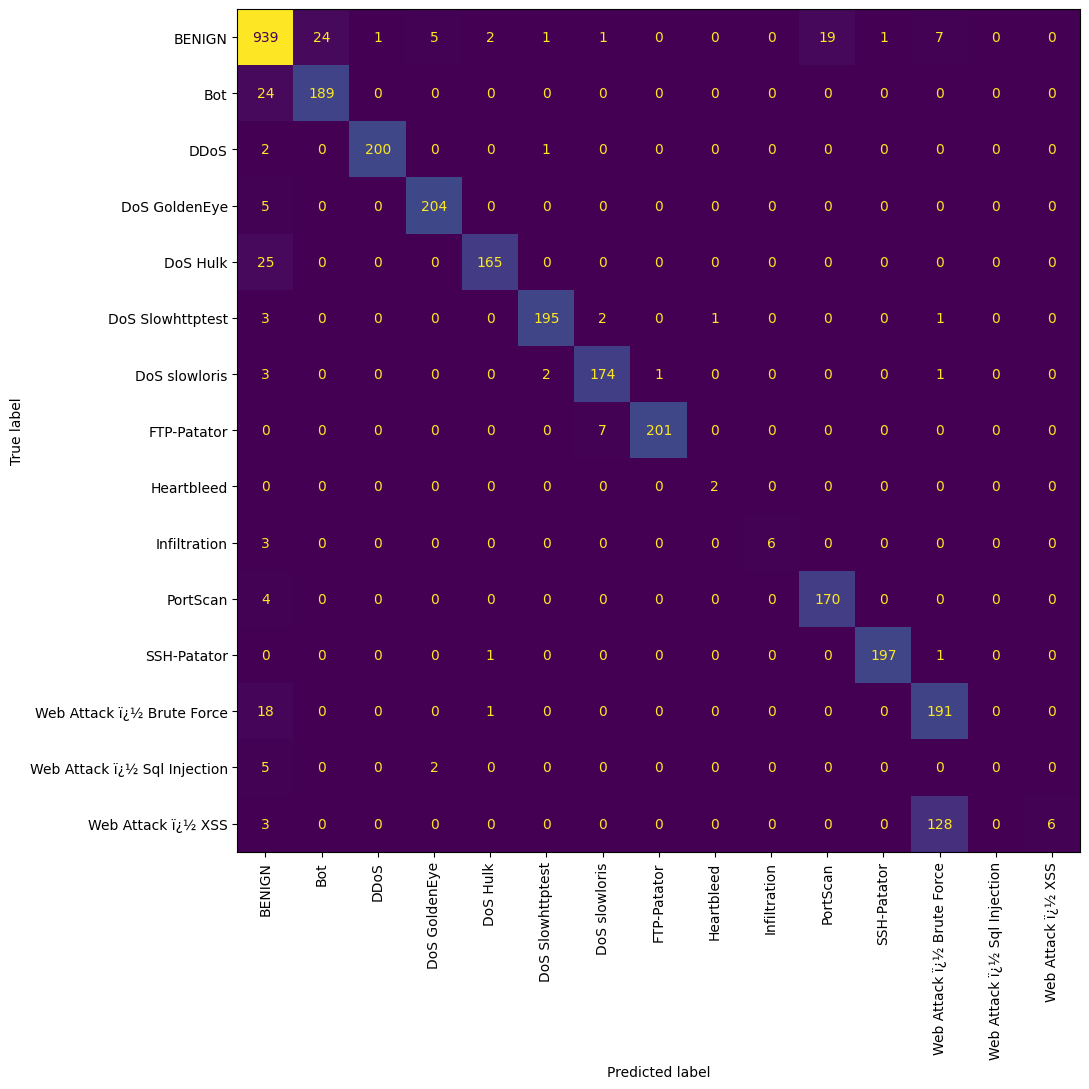

,run,accuracy,macro_f1,fpr
0,LightGBM notebook 04,0.94310,0.876400,NaN
1,V3 A5,0.88200,0.842400,0.152
2,V4 calibrated,0.90740,0.805700,0.085
3,V5 selected,0.90299,0.794638,0.061


Artifacts written: 49 (files and directories)


In [81]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay
fig,ax=plt.subplots(figsize=(12,11))
ConfusionMatrixDisplay(cm,display_labels=encoder.classes_).plot(ax=ax,xticks_rotation=90,values_format='d',colorbar=False)
fig.tight_layout();fig.savefig(OUTPUT/'test_confusion_matrix.png',dpi=170);plt.show()

# Reference numbers from earlier *pilot* outputs; these are not independently validated.
compare=pd.DataFrame([
 {'run':'LightGBM notebook 04','accuracy':.9431,'macro_f1':.8764,'fpr':np.nan},
 {'run':'V3 A5','accuracy':.8820,'macro_f1':.8424,'fpr':.1520},
 {'run':'V4 calibrated','accuracy':.9074,'macro_f1':.8057,'fpr':.0850},
 {'run':'V5 selected','accuracy':final_scores['accuracy'],'macro_f1':final_scores['macro_f1'],'fpr':final_scores['fpr']},
])
compare.to_csv(OUTPUT/'pilot_comparison.csv',index=False)
display(compare)
manifest={'mode':SEARCH_MODE,'budget':BUDGET,'features':features,'n_features':len(features),
 'classes':encoder.classes_.tolist(),'split_path':str(split_path),'split_sha256':sha,
 'n_trials':len(rows),'run_info':'Kaggle, feature-axis CNN; no chronology metadata',
 'selected':selected,'output_dir':str(OUTPUT)}
(OUTPUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
print('Artifacts written:',len(list(OUTPUT.rglob('*'))),'(files and directories)')
